# 邏輯斯迴歸圖解：ML 慢慢學 EP05 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v06-logistic-regression/notebook.ipynb)

這本 notebook 產生影片裡焚化爐範例的**每一張資料圖和每一個數字**。所有資料都是**模擬資料，非實廠數據**，不代表任何一座真實焚化廠。
This notebook generates every chart and number of the incinerator example in EP05 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated** and do not describe any real plant.

問題（接續 EP04 結尾）：**如果要預測的不是一個數字，而是「會不會超標」，該怎麼辦？**
這一集的問題：**接下來一小時的一氧化碳（CO）平均濃度，會不會超過廠內自訂的警戒值**。警戒值訂得比法規標準低，超過警戒值不等於違法，所以下面都說「超過警戒值」，不說「超標」。

| 段落 | 對應影片 |
|---|---|
| 1. 沿用 EP03 的模擬資料，再加上一氧化碳 | 第 2 段 |
| 2. 答案欄變成 0 或 1 | 第 2 段 |
| 3. 第一種做法：先猜數字，再和警戒值比 | 第 3 段 |
| 4. 第二種做法：直線直接配 0 和 1 | 第 3 段 |
| 5. S 形函數（Sigmoid）：把任何數變成 0 到 1 | 第 4 段 |
| 6. 交叉熵：為什麼不用平方誤差 | 第 6 段 |
| 7. 用梯度下降學權重 | 第 7 段 |
| 8. 鎖定設定（之後不再改） | — |
| 9. 測試集：全新的 20 天，只評估這一次 | 第 5、8 段 |
| 10. 匯出資料給影片使用 | — |

**流程紀律**：第 1–8 段只看訓練集和驗證集。測試集在第 8 段鎖定設定之後才產生，並且只評估一次。第一次產生的測試集（種子 2028，4 天）一次超過警戒值都沒有、無法評分，所以改用 5 個新種子共 20 天，詳見第 9 段。

參考：《廢棄物焚化爐戴奧辛管制及排放標準》第 7 條（爐溫、排氣含氧量、一氧化碳的操作條件）；EP03、EP04 notebook（同一個 repo 的 `v04-multiple-linear-regression`、`v05-overfitting`）。

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

PAPER, INK, RED, BLUE, AMBER, TEAL = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B", "#2A9D8F"
LABEL = "模擬資料，非實廠數據"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.unicode_minus": False})

def tag(ax):
    ax.text(0.99, 0.97, LABEL, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=RED)

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def cross_entropy(y, p):
    # 平均交叉熵（自然對數）。p 是模型說「會超過警戒值」的機率
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())

## 1. 沿用 EP03 的模擬資料，再加上一氧化碳
進料量、一次空氣流量、爐溫、含氧量、蒸汽流量的模擬方式和 EP03 **完全相同**（亂數種子 2026、14 天、每分鐘一筆）。
這一集**新增一氧化碳（CO）**，用另外一組亂數產生，所以舊的 5 個量一個數字都沒變。

一氧化碳是**燃燒不完全**的訊號。模擬的想法（數量級是為了示意而假設的）：

| 什麼時候 CO 會上升 | 模擬裡怎麼做 |
|---|---|
| 爐內氧氣不夠（放熱多、空氣相對少） | 含氧量（不含量測雜訊的值）越低，CO 越高 |
| 爐溫偏低（例如垃圾比較濕） | 爐溫越低，CO 稍微越高 |
| 爐床上看不到的擾動（垃圾堆得不均勻等） | 一個量不到的隨機擾動，大約 40 分鐘的相關時間 |

CO 的單位是 ppm（以排氣含氧量 10% 為參考基準的值，模擬）。
法規：《廢棄物焚化爐戴奧辛管制及排放標準》第 7 條要求煙道出口 CO **一小時動平均值低於 100 ppm**，排氣含氧量以 10% 為參考基準。
模擬值用一個「軟上限」讓一小時平均一定低於 100 ppm；這一集的警戒值 **30 ppm 是廠內自訂的示意值**，不是法規數字。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


進料量、空氣、爐溫、含氧量和 EP03 相同（感測器平均一致）
CO（每分鐘）：中位數 12.6、最大 72.2 ppm（模擬）
CO 一小時動平均：中位數 13.1、最大 53.3 ppm（法規：低於 100 ppm）


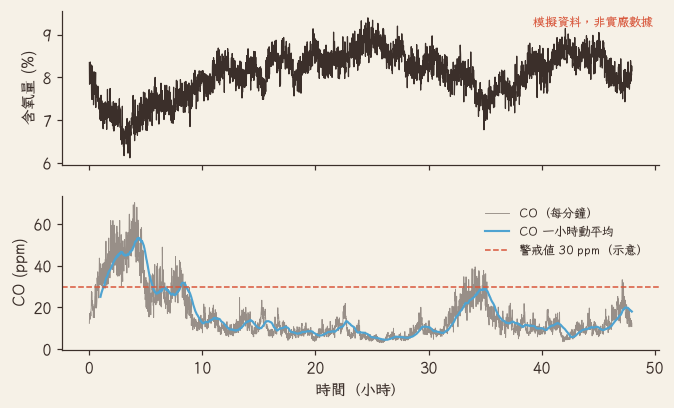

In [2]:
def lag(x, tau):
    # 一階延遲 (first-order lag)
    y = np.empty_like(x); y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = y[i - 1] + (x[i] - y[i - 1]) / tau
    return y

# CO 模擬參數（示意）
CO_BASE, CO_SMAX = 14.0, 1.5        # 平常約 14 ppm；指數部分的軟上限 1.5 → 一小時平均最多約 14 × e^1.5 ≈ 63 ppm
A_O2, A_TEMP = 1.8, 0.2             # 含氧量每低 1%、爐溫每低 10°C，對 log(CO) 的影響
TAU_U, SD_U = 40, 0.3               # 量不到的擾動：相關時間 40 分鐘

def simulate(seed, days):
    # 前半段和 EP03 notebook 第 1 段完全相同（亂數呼叫順序也相同）
    rng = np.random.default_rng(seed)
    N = days * 1440
    MU, SD = 2050.0, 150.0
    PHI = np.exp(-1 / 120)
    lhv = np.empty(N); lhv[0] = MU
    noise = rng.normal(0, SD * np.sqrt(1 - PHI ** 2), N)
    for i in range(1, N):
        lhv[i] = MU + PHI * (lhv[i - 1] - MU) + noise[i]
    lhv = np.clip(lhv, 1500, 2500)
    F_set = np.empty(N); i, level = 0, 12.5
    while i < N:
        length = int(rng.integers(120, 360))
        level = float(np.clip(level + rng.normal(0, 0.7), 10.5, 14.5))
        F_set[i:i + length] = level; i += length
    feed = lag(F_set, 15) + rng.normal(0, 0.15, N)
    trim = np.empty(N); trim[0] = 0.0
    PT = np.exp(-1 / 180)
    e_trim = rng.normal(0, 0.06 * np.sqrt(1 - PT ** 2), N)
    for i in range(1, N):
        trim[i] = PT * trim[i - 1] + e_trim[i]
    air = lag(3000 * F_set * (1 + trim), 5) + rng.normal(0, 400, N)
    Q0 = 12.5 * MU
    q = feed * lhv / Q0
    air_rel = air / (3000 * 12.5)
    temp = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1) + rng.normal(0, 5, N)
    o2 = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1) + rng.normal(0, 0.2, N)
    steam = lag(feed * lhv * 0.8 / 670 - 4 * (air_rel - 1), 10) + rng.normal(0, 0.3, N)
    raw = np.c_[feed, air, temp, o2]
    # 範圍檢查：爐溫 > 850°C、排氣含氧量 ≥ 6% 是法規；含氧量 < 10%、空氣 > 10000 是模擬自己設的範圍
    assert temp.min() > 850 and 6 <= o2.min() and o2.max() < 10 and air.min() > 10000

    # ---- EP05 新增：一氧化碳（另開亂數，不影響上面任何數值）----
    r2 = np.random.default_rng(seed + 500)
    o2_true = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1)     # 不含量測雜訊
    temp_true = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1)
    PU = np.exp(-1 / TAU_U)
    u = np.empty(N); u[0] = 0.0
    e_u = r2.normal(0, SD_U * np.sqrt(1 - PU ** 2), N)
    for i in range(1, N):
        u[i] = PU * u[i - 1] + e_u[i]
    s = A_O2 * (8.0 - o2_true) + A_TEMP * (960 - temp_true) / 10 + u
    s = CO_SMAX * np.tanh(s / CO_SMAX)                                # 軟上限
    co = CO_BASE * np.exp(s) * np.exp(r2.normal(0, 0.15, N))           # 量測雜訊
    co_hour = np.convolve(co, np.ones(60) / 60, mode="valid")          # 一小時動平均
    assert co_hour.max() < 100, "模擬的 CO 一小時平均必須低於法規的 100 ppm"
    return raw, steam, co

NAMES = ["進料量", "一次空氣流量", "爐溫", "含氧量"]
UNITS = ["t/h", "Nm³/h", "°C", "%"]
raw, steam, co = simulate(2026, 14)

# 確認舊資料和 EP03 一樣：比對 EP03 匯出的感測器平均（前 10 天訓練列）
H = 60
ep03 = Path("../v04-multiple-linear-regression/data/v04.json")
if ep03.exists():
    ref = json.loads(ep03.read_text(encoding="utf-8"))["sensors"]["mean"]
    assert np.allclose(raw[:10 * 1440 - H].mean(0), ref, atol=1e-3), "資料和 EP03 不一致"
    print("進料量、空氣、爐溫、含氧量和 EP03 相同（感測器平均一致）")

co_hour = np.convolve(co, np.ones(H) / H, mode="valid")
print(f"CO（每分鐘）：中位數 {np.median(co):.1f}、最大 {co.max():.1f} ppm（模擬）")
print(f"CO 一小時動平均：中位數 {np.median(co_hour):.1f}、最大 {co_hour.max():.1f} ppm（法規：低於 100 ppm）")

hours = np.arange(len(co)) / 60
show = hours < 48
fig, axs = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
axs[0].plot(hours[show], raw[show, 3], lw=0.8, color=INK); axs[0].set_ylabel("含氧量 (%)")
axs[1].plot(hours[show], co[show], lw=0.6, color=INK, alpha=0.5, label="CO（每分鐘）")
axs[1].plot(hours[H - 1:][show[H - 1:]], co_hour[show[H - 1:]], lw=1.4, color=BLUE, label="CO 一小時動平均")
axs[1].axhline(30, color=RED, ls="--", lw=1, label="警戒值 30 ppm（示意）")
axs[1].set_ylabel("CO (ppm)"); axs[1].set_xlabel("時間（小時）"); axs[1].legend(frameon=False, fontsize=8)
tag(axs[0]); plt.show()

## 2. 答案欄變成 0 或 1
每一列（每一分鐘）的答案：**接下來 60 分鐘的 CO 平均，有沒有超過 30 ppm**。超過記 1，沒超過記 0。
輸入和 EP03、EP04 一樣，只用**那一分鐘已經量到的** 4 個感測器（進料量、一次空氣流量、爐溫、含氧量），不偷看未來。

| 資料 | 用途 |
|---|---|
| 第 1–10 天，每分鐘一筆 | 訓練集：算權重 |
| 第 11–14 天，每分鐘一筆 | 驗證集：檢查、比較做法 |
| 另外模擬的 20 天（第 9 段才產生） | 測試集：最後只評估一次 |

訓練集最後 60 分鐘不用，因為它們的答案會用到驗證期的 CO。

In [3]:
THR = 30.0

def make_xy(raw, co):
    cs = np.cumsum(np.r_[0.0, co])
    rows = np.arange(len(co) - H)
    co_next = (cs[rows + 1 + H] - cs[rows + 1]) / H      # co[t+1 .. t+60] 的平均
    return raw[rows], co_next, (co_next > THR).astype(float)

X, co_next, y = make_xy(raw, co)
TR = np.arange(0, 10 * 1440 - H)
VA = np.arange(10 * 1440, 14 * 1440 - H)
assert TR.max() + H < VA.min()
print(f"訓練集 {len(TR):,} 筆，其中答案是 1（會超過警戒值）的有 {100 * y[TR].mean():.1f}%")
print(f"驗證集 {len(VA):,} 筆，其中答案是 1 的有 {100 * y[VA].mean():.1f}%")

# 標準化（EP03）：平均和標準差只用訓練集算
mu, sd = X[TR].mean(0), X[TR].std(0)
def design(rows, Xsrc=None):
    Xs = X if Xsrc is None else Xsrc
    return np.c_[np.ones(len(rows)), (Xs[rows] - mu) / sd]
A_tr, A_va = design(TR), design(VA)

訓練集 14,340 筆，其中答案是 1（會超過警戒值）的有 7.9%
驗證集 5,700 筆，其中答案是 1 的有 20.3%


## 3. 第一種做法：先猜數字，再和警戒值比
沿用 EP03 的線性迴歸，先猜「接下來一小時的 CO 平均是多少 ppm」，再拿去和 30 比。
問題：它只給一個數字，猜 28 ppm 和猜 12 ppm 都是「沒超過」，看不出**有多大把握**。

In [4]:
w_num, *_ = np.linalg.lstsq(A_tr, co_next[TR], rcond=None)
pred_num_va = A_va @ w_num
mae_num_va = float(np.abs(pred_num_va - co_next[VA]).mean())
print(f"驗證集：猜 CO 數字的平均絕對誤差 {mae_num_va:.1f} ppm")
near = np.abs(pred_num_va - THR) < 5
print(f"驗證集裡，猜的數字落在 {THR - 5:.0f}–{THR + 5:.0f} ppm（離警戒值不到 5 ppm）的時間占 {100 * near.mean():.0f}%；"
      f"這些時間裡真的超過警戒值的比例 {100 * y[VA][near].mean():.0f}%")

# 影片用的例子：驗證集裡「猜的數字比警戒值低一點，結果真的超過警戒值」的一分鐘
cand = np.where((pred_num_va > 25) & (pred_num_va < 29.5) & (co_next[VA] > 33))[0]
ex = int(cand[len(cand) // 2])
num_example = {"pred": round(float(pred_num_va[ex]), 1), "actual": round(float(co_next[VA][ex]), 1)}
print(f"例子：猜 {num_example['pred']} ppm（< 30，判定沒超過），實際 {num_example['actual']} ppm（超過）")

驗證集：猜 CO 數字的平均絕對誤差 4.9 ppm
驗證集裡，猜的數字落在 25–35 ppm（離警戒值不到 5 ppm）的時間占 25%；這些時間裡真的超過警戒值的比例 71%
例子：猜 25.6 ppm（< 30，判定沒超過），實際 38.1 ppm（超過）


## 4. 第二種做法：直線直接配 0 和 1
把答案 0 和 1 當成數字，用線性迴歸（最小平方法）直接配。為了畫在平面上，先只用**含氧量**一個輸入。

只用含氧量的直線：含氧量 6.1% 時輸出 0.51，9.6% 時輸出 -0.28
直線輸出小於 0 的含氧量範圍：8.4% 以上
4 個感測器的直線（驗證集）：輸出 -0.11 到 0.43，其中 3.0% 小於 0


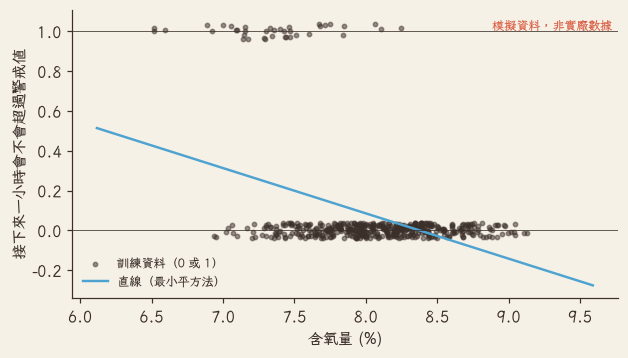

In [5]:
z_o2 = (X[:, 3] - mu[3]) / sd[3]
A1_tr = np.c_[np.ones(len(TR)), z_o2[TR]]
w_lin1, *_ = np.linalg.lstsq(A1_tr, y[TR], rcond=None)

o2_grid = np.linspace(X[TR, 3].min(), X[TR, 3].max(), 121)
zg = (o2_grid - mu[3]) / sd[3]
lin1_grid = w_lin1[0] + w_lin1[1] * zg
print(f"只用含氧量的直線：含氧量 {o2_grid[0]:.1f}% 時輸出 {lin1_grid[0]:.2f}，{o2_grid[-1]:.1f}% 時輸出 {lin1_grid[-1]:.2f}")
print(f"直線輸出小於 0 的含氧量範圍：{o2_grid[lin1_grid < 0].min():.1f}% 以上")

# 4 個感測器的直線，在驗證集上的輸出
w_lin4, *_ = np.linalg.lstsq(A_tr, y[TR], rcond=None)
lin4_va = A_va @ w_lin4
print(f"4 個感測器的直線（驗證集）：輸出 {lin4_va.min():.2f} 到 {lin4_va.max():.2f}，其中 {100 * (lin4_va < 0).mean():.1f}% 小於 0")

# 影片用的散點：訓練集每 30 分鐘取一筆
pts = TR[::30]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.scatter(X[pts, 3], y[pts] + np.random.default_rng(0).uniform(-0.04, 0.04, len(pts)), s=8, color=INK, alpha=0.5, label="訓練資料（0 或 1）")
ax.plot(o2_grid, lin1_grid, color=BLUE, lw=1.6, label="直線（最小平方法）")
ax.axhline(0, color=INK, lw=0.5); ax.axhline(1, color=INK, lw=0.5)
ax.set_xlabel("含氧量 (%)"); ax.set_ylabel("接下來一小時會不會超過警戒值"); ax.legend(frameon=False, fontsize=8); tag(ax)
plt.show()

## 5. S 形函數（Sigmoid）：把任何數變成 0 到 1
先像 EP03 一樣算 $z = w_1x_1 + \dots + b$，再丟進 S 形函數：

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

$z$ 很大時 $p$ 接近 1，$z$ 很小（很負）時 $p$ 接近 0，$z = 0$ 時 $p = 0.5$。$p$ 讀成「接下來一小時會超過警戒值的機率」。
下面一樣只用含氧量一個輸入（權重的學法在第 6、7 段說明；這裡用牛頓法直接求出最好的權重，只為了畫圖）。

只用含氧量的 S 形曲線：含氧量 7.15% 時機率 = 0.5；6.1% 時 0.99，9.6% 時 0.000


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


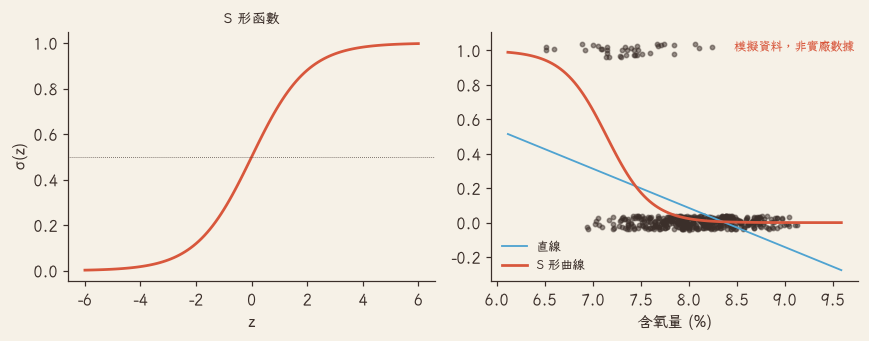

In [6]:
def fit_newton(A, yv, iters=30):
    # 交叉熵最小的權重（牛頓法），用來核對梯度下降的結果
    w = np.zeros(A.shape[1])
    for _ in range(iters):
        p = sigmoid(A @ w)
        g = A.T @ (p - yv)
        Hm = (A * (p * (1 - p))[:, None]).T @ A
        w -= np.linalg.solve(Hm, g)
    return w

w_log1 = fit_newton(A1_tr, y[TR])
log1_grid = sigmoid(w_log1[0] + w_log1[1] * zg)
o2_half = float(mu[3] - w_log1[0] / w_log1[1] * sd[3])
print(f"只用含氧量的 S 形曲線：含氧量 {o2_half:.2f}% 時機率 = 0.5；"
      f"{o2_grid[0]:.1f}% 時 {log1_grid[0]:.2f}，{o2_grid[-1]:.1f}% 時 {log1_grid[-1]:.3f}")
assert log1_grid.min() > 0 and log1_grid.max() < 1

z_demo = np.linspace(-6, 6, 121)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2))
axs[0].plot(z_demo, sigmoid(z_demo), color=RED, lw=1.8); axs[0].set_xlabel("z"); axs[0].set_ylabel("σ(z)")
axs[0].axhline(0.5, color=INK, lw=0.5, ls=":"); axs[0].set_title("S 形函數", fontsize=9)
axs[1].scatter(X[pts, 3], y[pts] + np.random.default_rng(0).uniform(-0.04, 0.04, len(pts)), s=8, color=INK, alpha=0.5)
axs[1].plot(o2_grid, lin1_grid, color=BLUE, lw=1.2, label="直線")
axs[1].plot(o2_grid, log1_grid, color=RED, lw=1.8, label="S 形曲線")
axs[1].set_xlabel("含氧量 (%)"); axs[1].legend(frameon=False, fontsize=8); tag(axs[1])
plt.tight_layout(); plt.show()

## 6. 交叉熵：為什麼不用平方誤差
答案是 1 時，模型說的機率是 $p$；答案是 0 時，模型給「正確答案」的機率是 $1-p$。
**交叉熵 = −log（模型給正確答案的機率）**，整批資料取平均：

$$L = -\frac{1}{n}\sum_i \big[y_i \log p_i + (1-y_i)\log(1-p_i)\big]$$

給正確答案的機率越接近 1，罰得越少；越接近 0，罰得越重，而且沒有上限。平方誤差 $(p-y)^2$ 最多只罰到 1。

**更重要的差別在「推權重的力道」**（梯度下降靠梯度移動權重）。$p = \sigma(z)$，對 $z$ 微分：
- 交叉熵：$\frac{\partial L}{\partial z} = p - y$
- 平方誤差：$\frac{\partial (p-y)^2}{\partial z} = 2(p - y)\,p(1-p)$

猜錯又很有把握時（例如答案是 1，$p = 0.01$），$p(1-p)$ 幾乎是 0，平方誤差幾乎推不動權重；交叉熵的力道仍然接近 1。

模型給正確答案的機率   交叉熵   平方誤差
          0.99       0.01      0.00
          0.90       0.11      0.01
          0.50       0.69      0.25
          0.10       2.30      0.81
          0.01       4.61      0.98

答案是 1 時，模型說 p   交叉熵的力道 |p − y|   平方誤差的力道 |2(p − y)p(1 − p)|
              0.01                0.990                       0.0196
              0.10                0.900                       0.1620
              0.50                0.500                       0.2500
              0.90                0.100                       0.0180
猜錯又很有把握（p = 0.01）：交叉熵的力道是平方誤差的 51 倍


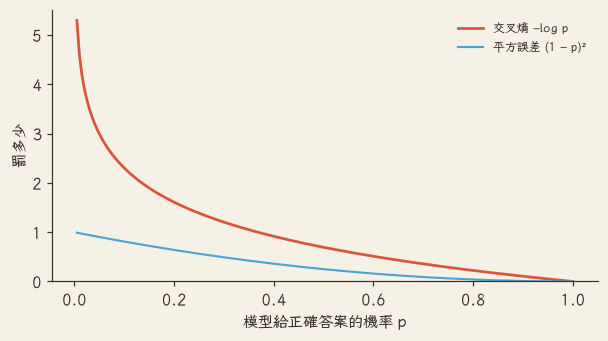

In [7]:
cases = []
for p_right in [0.99, 0.9, 0.5, 0.1, 0.01]:
    cases.append({"p_right": p_right, "ce": float(-np.log(p_right)), "se": float((1 - p_right) ** 2)})
print("模型給正確答案的機率   交叉熵   平方誤差")
for c in cases:
    print(f"{c['p_right']:>14.2f}   {c['ce']:>8.2f}   {c['se']:>7.2f}")

# 推權重的力道：答案是 1，模型說 p
push = []
for p in [0.01, 0.1, 0.5, 0.9]:
    push.append({"p": p, "grad_ce": float(abs(p - 1)), "grad_se": float(abs(2 * (p - 1) * p * (1 - p)))})
print("\n答案是 1 時，模型說 p   交叉熵的力道 |p − y|   平方誤差的力道 |2(p − y)p(1 − p)|")
for g in push:
    print(f"{g['p']:>18.2f}   {g['grad_ce']:>18.3f}   {g['grad_se']:>26.4f}")
print(f"猜錯又很有把握（p = 0.01）：交叉熵的力道是平方誤差的 {push[0]['grad_ce'] / push[0]['grad_se']:.0f} 倍")

p_grid = np.linspace(0.005, 1, 200)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(p_grid, -np.log(p_grid), color=RED, lw=1.8, label="交叉熵 −log p")
ax.plot(p_grid, (1 - p_grid) ** 2, color=BLUE, lw=1.4, label="平方誤差 (1 − p)²")
ax.set_xlabel("模型給正確答案的機率 p"); ax.set_ylabel("罰多少"); ax.set_ylim(0, 5.5); ax.legend(frameon=False, fontsize=8)
plt.show()

## 7. 用梯度下降學權重
4 個感測器都用上（已標準化，EP03），權重從 0 開始，用梯度下降（EP01）把**訓練集的交叉熵**往下推。
交叉熵對權重的梯度很簡單：$\nabla L = \frac{1}{n}A^\top(p - y)$（$A$ 是加了一欄 1 的輸入）。
每一步也記下驗證集的交叉熵（只看，不拿來改任何東西）。最後和牛頓法的答案核對。

梯度下降的權重： [-6.621 -1.753 -2.232  1.468 -0.366]
牛頓法的權重：   [-6.621 -1.753 -2.232  1.468 -0.366]
（沒有安裝 scikit-learn，略過這個核對）

交叉熵：一開始（全部猜 0.5）0.693；學完 訓練 0.119、驗證 0.293
對照：每一分鐘都猜「訓練集的超過警戒值比例 0.079」，驗證集交叉熵 0.581
注意：4 個感測器彼此相關（爐溫和含氧量都跟著放熱量和空氣量變），所以單一權重的正負和大小不適合直接解讀。


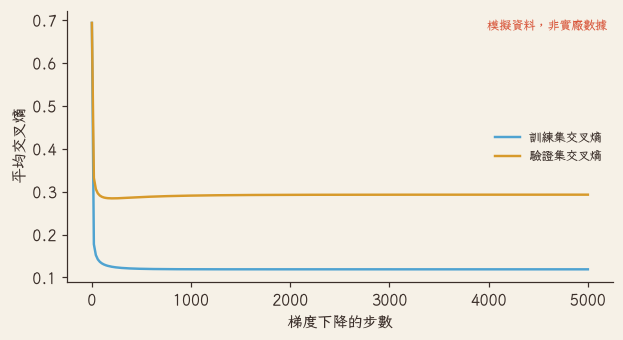

In [8]:
LR, ITERS = 1.0, 5000
w = np.zeros(A_tr.shape[1])
hist = {"it": [], "train": [], "val": []}
for it in range(ITERS + 1):
    if it % 20 == 0:
        hist["it"].append(it)
        hist["train"].append(cross_entropy(y[TR], sigmoid(A_tr @ w)))
        hist["val"].append(cross_entropy(y[VA], sigmoid(A_va @ w)))
    if it < ITERS:
        p = sigmoid(A_tr @ w)
        w -= LR * A_tr.T @ (p - y[TR]) / len(TR)
w_gd = w.copy()
w_nt = fit_newton(A_tr, y[TR])
print("梯度下降的權重：", np.round(w_gd, 3))
print("牛頓法的權重：  ", np.round(w_nt, 3))
assert np.abs(w_gd - w_nt).max() < 0.05 and cross_entropy(y[TR], sigmoid(A_tr @ w_gd)) - cross_entropy(y[TR], sigmoid(A_tr @ w_nt)) < 1e-4, "梯度下降還沒收斂到最好的權重"
try:
    from sklearn.linear_model import LogisticRegression
    sk = LogisticRegression(C=1e12, max_iter=5000).fit((X[TR] - mu) / sd, y[TR])
    print("scikit-learn 的權重：", np.round(np.r_[sk.intercept_, sk.coef_[0]], 3))
except ImportError:
    print("（沒有安裝 scikit-learn，略過這個核對）")

base_rate = float(y[TR].mean())
print(f"\n交叉熵：一開始（全部猜 0.5）{hist['train'][0]:.3f}；學完 訓練 {hist['train'][-1]:.3f}、驗證 {hist['val'][-1]:.3f}")
print(f"對照：每一分鐘都猜「訓練集的超過警戒值比例 {base_rate:.3f}」，驗證集交叉熵 {cross_entropy(y[VA], np.full(len(VA), base_rate)):.3f}")
print("注意：4 個感測器彼此相關（爐溫和含氧量都跟著放熱量和空氣量變），所以單一權重的正負和大小不適合直接解讀。")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(hist["it"], hist["train"], color=BLUE, lw=1.6, label="訓練集交叉熵")
ax.plot(hist["it"], hist["val"], color=AMBER, lw=1.6, label="驗證集交叉熵")
ax.set_xlabel("梯度下降的步數"); ax.set_ylabel("平均交叉熵"); ax.legend(frameon=False, fontsize=8); tag(ax)
plt.show()

## 8. 鎖定設定（之後不再改）
到這裡為止只用了訓練集和驗證集。現在把要帶去測試的模型**先寫死**：

- 輸入：4 個感測器，標準化（平均、標準差用訓練集）
- 模型：邏輯斯迴歸，梯度下降學習率 1.0、5000 步（權重如上）
- 警戒值：接下來一小時 CO 平均 > 30 ppm（示意）
- 要報告的：測試集交叉熵、機率分組後實際超過警戒值的比例（「說 70%，是不是真的大約 70%」）、不同門檻下發出警報的時間比例

門檻要訂多少、兩種錯（漏報和誤報）怎麼取捨，是下一集的主題；這一集只看「門檻一改，警報就跟著變多或變少」。

In [9]:
LOCK = {"features": NAMES, "mu": mu.tolist(), "sd": sd.tolist(), "w": w_gd.tolist(), "lr": LR, "iters": ITERS, "thr_ppm": THR}
CAL_BINS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
DECISION = [0.3, 0.5, 0.7]
print(json.dumps({k: (np.round(v, 4).tolist() if isinstance(v, list) and k != "features" else v) for k, v in LOCK.items()}, ensure_ascii=False))

{"features": ["進料量", "一次空氣流量", "爐溫", "含氧量"], "mu": [13.0984, 38792.4532, 965.5008, 8.0328], "sd": [1.1139, 4259.6242, 19.0719, 0.4745], "w": [-6.6207, -1.7533, -2.2322, 1.468, -0.3662], "lr": 1.0, "iters": 5000, "thr_ppm": 30.0}


## 9. 測試
### 9.1 第一次測試（種子 2028，4 天）：一次都沒超過警戒值
第一次用種子 2028 模擬 4 天當測試集，結果這 4 天**沒有任何一分鐘**超過警戒值（答案全是 0）。這 4 天仍然算得出交叉熵、看得到誤報，但沒有超過的案例，就沒辦法檢查漏報，也沒辦法檢查「說 70%，是不是大約 70%」。
原因：超過警戒值的比例跟著操作員慢慢調整的進料設定值飄動，不同時段差很多（訓練期約 8%、驗證期約 20%、這 4 天 0%）。鎖定設定之前沒有檢查這件事，是這本 notebook 的疏忽。

處理方式：模型**不改**（第 8 段已鎖定）。這 4 天已經看過，只留下紀錄、不再拿來評分；另外產生一個**更大的新測試集**，大小在看之前就先決定（9.2）。

In [10]:
SEEN_SEED = 2028
raw_s, _, co_s = simulate(SEEN_SEED, 5)
Xs_all, _, ys_all = make_xy(raw_s, co_s)
SEG = np.arange(1440, 5 * 1440 - H)                # 每段：模擬 5 天，丟掉第 1 天
p_seen = sigmoid(np.c_[np.ones(len(SEG)), (Xs_all[SEG] - mu) / sd] @ w_gd)
seen = {"seed": SEEN_SEED, "n": int(len(SEG)), "pos_rate": float(ys_all[SEG].mean()), "p_max": float(p_seen.max()),
        "ce": cross_entropy(ys_all[SEG], p_seen), "alarm_05": float((p_seen >= 0.5).mean())}
print(f"種子 {SEEN_SEED} 的 4 天：答案是 1 的占 {100 * seen['pos_rate']:.1f}%；模型說的機率最高 {seen['p_max']:.3f}（已看過，不再評分）")
print(f"這 4 天的交叉熵 {seen['ce']:.3f}；門檻 0.5 時發出警報的時間 {100 * seen['alarm_05']:.1f}%（全部都是誤報，因為沒有超過的案例）")

種子 2028 的 4 天：答案是 1 的占 0.0%；模型說的機率最高 0.156（已看過，不再評分）
這 4 天的交叉熵 0.002；門檻 0.5 時發出警報的時間 0.0%（全部都是誤報，因為沒有超過的案例）


### 9.2 新的測試集：5 段 × 4 天 = 20 天，只評估這一次
從種子 2029 往上，取**前 5 個模擬結果在設定範圍內**的種子（爐溫 > 850°C、排氣含氧量 ≥ 6% 是法規要求；含氧量 < 10%、一次空氣 > 10,000 Nm³/h 是這套模擬自己設的範圍；超出範圍的種子跳過並記下來，這個規則只看感測器範圍，不看答案或分數），每段一樣模擬 5 天、丟掉第 1 天，共 20 天。模型、警戒值、機率分組、門檻都照第 8 段，**不再調整任何東西**。
影片要放的 48 小時用事先定好的規則挑：**20 天裡實際超過警戒值分鐘數最多的連續 48 小時**（只看答案，不看模型的分數）。

測試用的種子：[2030, 2031, 2032, 2033, 2034]；因為超出模擬設定範圍而跳過的：[2029]
各段答案是 1 的比例： 2030：3.3%、2031：1.6%、2032：26.1%、2033：38.5%、2034：0.0%
測試集 28,500 筆（20 天、每分鐘一筆），答案是 1 的占 13.9%
測試集交叉熵 0.185（對照：每分鐘都猜訓練集比例 0.079 → 0.424）
模型輸出的機率：0.000 到 0.991（一定在 0 和 1 之間）

模型說的機率   筆數   平均機率   實際超過警戒值比例
  0.0–0.2    23380       0.02         0.04
  0.2–0.4     1748       0.29         0.34
  0.4–0.6     1178       0.50         0.56
  0.6–0.8     1161       0.70         0.76
  0.8–1.0     1033       0.89         0.94

門檻   發出警報的時間比例
  0.3   14.5%
  0.5   9.8%
  0.7   5.6%

影片用的 48 小時：種子 2033 那一段的第 2.1–50.1 小時，裡面有 1529 分鐘超過警戒值


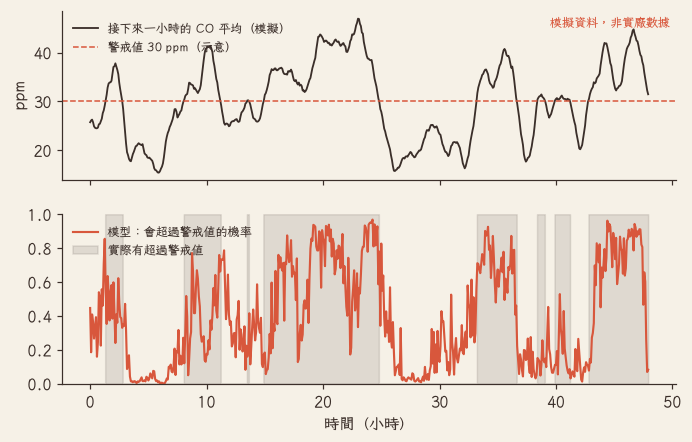

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


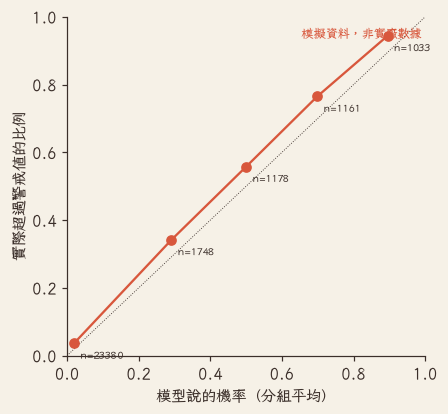

In [11]:
TEST_SEEDS, SKIPPED = [], []
sims = {}
sd_ = 2029
while len(TEST_SEEDS) < 5:
    try:
        sims[sd_] = simulate(sd_, 5)
        TEST_SEEDS.append(sd_)
    except AssertionError:
        SKIPPED.append(sd_)                      # 模擬結果超出設定範圍：跳過
    sd_ += 1
print(f"測試用的種子：{TEST_SEEDS}；因為超出模擬設定範圍而跳過的：{SKIPPED or '無'}")
segs = []
for sd_ in TEST_SEEDS:
    raw_t, _, co_t = sims[sd_]
    Xt_all, co_next_t_all, yt_all = make_xy(raw_t, co_t)
    Xt, co_next_t, yt = Xt_all[SEG], co_next_t_all[SEG], yt_all[SEG]
    p_t = sigmoid(np.c_[np.ones(len(SEG)), (Xt - mu) / sd] @ w_gd)
    segs.append({"seed": sd_, "co_next": co_next_t, "y": yt, "p": p_t})
yt = np.concatenate([g["y"] for g in segs])
p_te = np.concatenate([g["p"] for g in segs])
seg_rates = [{"seed": g["seed"], "pos_rate": float(g["y"].mean())} for g in segs]
print("各段答案是 1 的比例：", "、".join(f"{r['seed']}：{100 * r['pos_rate']:.1f}%" for r in seg_rates))

test = {
    "n": int(len(yt)),
    "pos_rate": float(yt.mean()),
    "ce": cross_entropy(yt, p_te),
    "ce_base": cross_entropy(yt, np.full(len(yt), base_rate)),
    "p_min": float(p_te.min()), "p_max": float(p_te.max()),
}
print(f"測試集 {test['n']:,} 筆（20 天、每分鐘一筆），答案是 1 的占 {100 * test['pos_rate']:.1f}%")
print(f"測試集交叉熵 {test['ce']:.3f}（對照：每分鐘都猜訓練集比例 {base_rate:.3f} → {test['ce_base']:.3f}）")
print(f"模型輸出的機率：{test['p_min']:.3f} 到 {test['p_max']:.3f}（一定在 0 和 1 之間）")

cal = []
print("\n模型說的機率   筆數   平均機率   實際超過警戒值比例")
for a, b in zip(CAL_BINS[:-1], CAL_BINS[1:]):
    m = (p_te >= a) & ((p_te < b) if b < 1 else (p_te <= b))
    row = {"lo": a, "hi": b, "n": int(m.sum()),
           "mean_p": float(p_te[m].mean()) if m.any() else None, "freq": float(yt[m].mean()) if m.any() else None}
    cal.append(row)
    if m.any():
        print(f"  {a:.1f}–{b:.1f}    {row['n']:>5}   {row['mean_p']:>8.2f}   {row['freq']:>10.2f}")

alarm = []
print("\n門檻   發出警報的時間比例")
for t in DECISION:
    share = float((p_te >= t).mean())
    alarm.append({"thr": t, "share": share})
    print(f"  {t:.1f}   {100 * share:.1f}%")

# 影片的 48 小時：只看答案，挑超過警戒值分鐘數最多的連續 48 小時（不跨段）
W = 2 * 1440
best = None
for k, g in enumerate(segs):
    c = np.cumsum(np.r_[0, g["y"]])
    sums = c[W:] - c[:-W]
    j = int(sums.argmax())
    if best is None or sums[j] > best[2]:
        best = (k, j, int(sums[j]))
k_win, j_win, n_win = best
g = segs[k_win]
sel = np.arange(j_win, j_win + W, 5)              # 每 5 分鐘一點
print(f"\n影片用的 48 小時：種子 {g['seed']} 那一段的第 {j_win / 60:.1f}–{(j_win + W) / 60:.1f} 小時，裡面有 {n_win} 分鐘超過警戒值")

t_rel = (sel - j_win) / 60
fig, axs = plt.subplots(2, 1, figsize=(7.2, 4.4), sharex=True)
axs[0].plot(t_rel, g["co_next"][sel], color=INK, lw=1.2, label="接下來一小時的 CO 平均（模擬）")
axs[0].axhline(THR, color=RED, ls="--", lw=1, label="警戒值 30 ppm（示意）")
axs[0].set_ylabel("ppm"); axs[0].legend(frameon=False, fontsize=8)
axs[1].plot(t_rel, g["p"][sel], color=RED, lw=1.4, label="模型：會超過警戒值的機率")
axs[1].fill_between(t_rel, 0, g["y"][sel], color=INK, alpha=0.12, step="mid", label="實際有超過警戒值")
axs[1].set_ylim(0, 1); axs[1].set_xlabel("時間（小時）"); axs[1].legend(frameon=False, fontsize=8)
tag(axs[0]); plt.show()

fig, ax = plt.subplots(figsize=(4.2, 4))
ok = [c for c in cal if c["n"] > 0]
ax.plot([0, 1], [0, 1], color=INK, lw=0.6, ls=":")
ax.plot([c["mean_p"] for c in ok], [c["freq"] for c in ok], "o-", color=RED)
for c in ok:
    ax.annotate(f"n={c['n']}", (c["mean_p"], c["freq"]), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.set_xlabel("模型說的機率（分組平均）"); ax.set_ylabel("實際超過警戒值的比例"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); tag(ax)
plt.show()

## 10. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖。颱風假、氣象署「暴風侵襲機率」的說明直接引自官方網站，不是這本 notebook 算的。

In [12]:
def rn(v, d=4): return [round(float(x), d) for x in np.ravel(v)]
def r6(v): return round(float(v), 6)

vsel = np.arange(0, 2 * 1440, 5)                # 驗證集前 2 天，每 5 分鐘一點（第 2、3 段的圖）
out = {
    "meta": {"seed_train": 2026, "seed_test": TEST_SEEDS, "seed_test_seen_no_positive": SEEN_SEED, "seed_test_skipped_out_of_range": SKIPPED, "horizon_min": H, "thr_ppm": THR, "law_ppm": 100,
             "train_days": 10, "val_days": 4, "test_days": 20, "n_train": int(len(TR)), "n_val": int(len(VA)), "n_test": test["n"],
             "simulated": True, "label": LABEL, "co_unit": "ppm（以排氣含氧量 10% 為參考基準，模擬）",
             "co_hour_max_train_val": round(float(co_hour.max()), 1), "co_median": round(float(np.median(co)), 1)},
    "sensors": NAMES,
    "rates": {"train": r6(y[TR].mean()), "val": r6(y[VA].mean()), "test": r6(test["pos_rate"])},
    "val_series": {"t_h": rn(vsel / 60, 3), "co_next": rn(co_next[VA][vsel], 1), "y": [int(v) for v in y[VA][vsel]],
                   "pred_num": rn(pred_num_va[vsel], 1),
                   # 影片第 2 段（2.3）：同一段時間的含氧量（量測值）和 CO（過去 5 分鐘平均），只用來畫圖
                   "o2": rn(X[VA][vsel, 3], 2), "co5": rn(np.convolve(co, np.ones(5) / 5, mode="full")[:len(co)][VA][vsel], 1)},
    "num_model": {"mae_val": round(mae_num_va, 2), "near_share": r6(near.mean()), "near_pos": r6(y[VA][near].mean()), "example": num_example},
    "demo1d": {"o2_pts": rn(X[pts, 3], 2), "y_pts": [int(v) for v in y[pts]], "o2_grid": rn(o2_grid, 3),
               "lin": rn(lin1_grid, 3), "logit": rn(log1_grid, 4), "o2_half": round(o2_half, 2),
               "lin_at_max_o2": round(float(lin1_grid[-1]), 2), "lin_at_min_o2": round(float(lin1_grid[0]), 2)},
    "lin4_val": {"min": round(float(lin4_va.min()), 2), "max": round(float(lin4_va.max()), 2), "neg_share": r6((lin4_va < 0).mean())},
    "sigmoid": {"z": rn(z_demo, 2), "p": rn(sigmoid(z_demo), 4)},
    "ce_cases": [{k: r6(v) for k, v in c.items()} for c in cases],
    "ce_push": [{k: r6(v) for k, v in g.items()} for g in push],
    "ce_curve": {"p": rn(p_grid, 4), "ce": rn(-np.log(p_grid), 4), "se": rn((1 - p_grid) ** 2, 4)},
    "gd": {"lr": LR, "iters": ITERS, "it": hist["it"], "train": rn(hist["train"], 4), "val": rn(hist["val"], 4),
           "w": rn(w_gd, 4), "w_newton": rn(w_nt, 4), "ce_base_val": r6(cross_entropy(y[VA], np.full(len(VA), base_rate)))},
    "lock": {k: (rn(v, 6) if k in ("mu", "sd", "w") else v) for k, v in LOCK.items()},
    "test": {**{k: (r6(v) if isinstance(v, float) else v) for k, v in test.items()},
             "calibration": [{k: (r6(v) if isinstance(v, float) else v) for k, v in c.items()} for c in cal],
             "alarm": [{k: r6(v) for k, v in a.items()} for a in alarm]},
    "test_first_seen": {k: (r6(v) if isinstance(v, float) else v) for k, v in seen.items()},
    "test_seg_rates": [{"seed": r["seed"], "pos_rate": r6(r["pos_rate"])} for r in seg_rates],
    "test_series": {"seed": g["seed"], "start_h": round(j_win / 60, 2), "pos_minutes": n_win, "t_h": rn(t_rel, 3),
                    "co_next": rn(g["co_next"][sel], 1), "y": [int(v) for v in g["y"][sel]], "p": rn(g["p"][sel], 4)},
}
Path("data").mkdir(exist_ok=True)
Path("data/v06.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print(f"已匯出 data/v06.json（{Path('data/v06.json').stat().st_size / 1024:.0f} KB）")

已匯出 data/v06.json（54 KB）
